# 📊 Sentiment Analysis of MBG Tweets
## Four methods, one sarcasm guard, and why word lists fall short

**Author:** Fachlevi Asclumb | [GitHub](https://github.com/Asclumb) | Text Mining course project, Institut Teknologi Kalimantan

We classify 1,000 Indonesian tweets about the Free Nutritious Meals (MBG) program with VADER, SentiWordNet, InSet and IndoBERT, plus a custom rule-based Sarcasm Guard. Because 82.7% of tweets are negative, F1-macro (not accuracy) is the main metric.

*🇮🇩 Kami mengklasifikasikan 1.000 tweet berbahasa Indonesia tentang program MBG dengan VADER, SentiWordNet, InSet, dan IndoBERT, ditambah Sarcasm Guard berbasis aturan. Karena 82,7% tweet bernada negatif, metrik utamanya F1-macro, bukan akurasi.*

> **Files needed / File yang dibutuhkan:** `MBGAsing.csv` · `kamus_slang_indonesia.csv` · `kamus_sarcasm_guard.csv` · `kamus_inset_indonesia.csv`
> Public tweets, used for academic purposes only. / *Tweet publik, hanya untuk keperluan akademik.*

## 1. Setup & Editable Dictionaries

### 1.1 Install and Import Libraries
Auto-installs missing packages so the notebook runs on a fresh machine or Colab.

*🇮🇩 Paket yang belum ada dipasang otomatis supaya notebook bisa jalan di mesin baru atau Colab.*

In [1]:
# ── Install Otomatis & Import Library ─────────────────────────
import sys
import subprocess

# Pengecekan khusus untuk IndoBERT (transformers & torch)
try:
    import transformers
    import torch
    print("✅ Transformers dan Torch sudah tersedia")
except ImportError:
    print("⏳ Modul transformers/torch belum ada. Memulai proses download & install otomatis...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "transformers", "torch"])
    print("✅ Instalasi Transformers dan Torch berhasil!")

# Pengecekan dependency lain secara umum
try:
    import vaderSentiment
    import emoji
except ImportError:
    print("⏳ Menginstall requirement tambahan lainnya...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "vaderSentiment", "nltk", "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn", "emoji", "openpyxl", "wordcloud"])

import pandas as pd
import numpy as np
import re, string, warnings, ast, time
from collections import Counter, defaultdict

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import emoji

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

try:
    from wordcloud import WordCloud
    WORDCLOUD_AVAILABLE = True
    print("✅ WordCloud tersedia")
except ImportError:
    WORDCLOUD_AVAILABLE = False
    print("⚠  WordCloud tidak tersedia")

plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['font.family']   = 'DejaVu Sans'
sns.set_style("whitegrid")

# ── Label mapping global ───────────────────────────────────────
LABEL_MAP   = {'positif': 2, 'netral': 1, 'negatif': 0}
LABEL_INV   = {v: k for k, v in LABEL_MAP.items()}
LABEL_NAME  = {0: 'NEG', 1: 'NET', 2: 'POS'}
LABELS_ORDER = ['negatif', 'netral', 'positif']
COLORS = {'negatif': '#2C5EAD', 'netral': '#1591DC', 'positif': '#4BB8FA'}
METHOD_COLORS = ['#2C5EAD', '#1591DC', '#4BB8FA', '#C4E2F5']

print("✅ Library berhasil diimport")
print(f"   pandas {pd.__version__} · numpy {np.__version__}")


✅ Transformers dan Torch sudah tersedia
⏳ Menginstall requirement tambahan lainnya...
✅ WordCloud tersedia
✅ Library berhasil diimport
   pandas 2.2.3 · numpy 2.1.3


### 1.2 Load the Three CSV Dictionaries
Slang normalization, Sarcasm Guard and InSet live in plain CSVs, so they can be edited without touching code.

*🇮🇩 Kamus slang, Sarcasm Guard, dan InSet disimpan di CSV, jadi bisa diedit tanpa mengubah kode.*

In [2]:
# ── Load kamus slang ───────────────────────────────────────────
df_slang = pd.read_csv('kamus_slang_indonesia.csv')
SLANG_DICT = {}
for _, row in df_slang.iterrows():
    baku = str(row['kata_baku']).strip()
    SLANG_DICT[str(row['kata_slang']).strip()] = baku if baku not in ('nan','') else ''

# ── Load kamus sarcasm guard ───────────────────────────────────
df_sg = pd.read_csv('kamus_sarcasm_guard.csv')
SARCASM_LEXICON     = {}
CONTRASTIVE_PATTERNS = []
IRONY_EMOJIS        = {}
CONTRASTIVE_CONJ    = {}

for _, row in df_sg.iterrows():
    k = str(row['teks']).strip()
    b = float(row['bobot'])
    if row['komponen'] == 'leksikon':
        SARCASM_LEXICON[k] = b
    elif row['komponen'] == 'pola_regex':
        CONTRASTIVE_PATTERNS.append((k, b))
    elif row['komponen'] == 'emoji_ironi':
        desc = str(row['keterangan']).split('—')[0].strip().lower().replace(' ','_')
        IRONY_EMOJIS[k] = b
        IRONY_EMOJIS[desc] = b
    elif row['komponen'] == 'konjungsi':
        CONTRASTIVE_CONJ[k] = b

# ── Load kamus InSet ───────────────────────────────────────────
df_inset = pd.read_csv('kamus_inset_indonesia.csv')
INSET_DICT = dict(zip(df_inset['kata'].str.strip(), df_inset['skor'].astype(float)))

print("✅ Kamus berhasil dimuat")
print(f"   Slang dict   : {len(SLANG_DICT):>4} entri")
print(f"   Sarcasm lex  : {len(SARCASM_LEXICON):>4} entri")
print(f"   Pola regex   : {len(CONTRASTIVE_PATTERNS):>4} pola")
print(f"   Emoji ironi  : {len(IRONY_EMOJIS):>4} entri")
print(f"   Konjungsi    : {len(CONTRASTIVE_CONJ):>4} kata")
print(f"   InSet dict   : {len(INSET_DICT):>4} entri")


✅ Kamus berhasil dimuat
   Slang dict   :  247 entri
   Sarcasm lex  :   79 entri
   Pola regex   :   27 pola
   Emoji ironi  :    0 entri
   Konjungsi    :   22 kata
   InSet dict   : 9242 entri


## 2. The Data: 83% of Tweets Are Negative, So Accuracy Misleads

### 2.1 Load the Dataset
Check size, missing values and class balance first, since imbalance decides which metric we can trust.

*🇮🇩 Cek ukuran data, missing values, dan keseimbangan kelas lebih dulu, karena ketimpangan menentukan metrik yang layak dipakai.*

In [4]:
# ── Load dataset ───────────────────────────────────────────────
df = pd.read_csv('MBGAsing.csv', sep=';')
df['label_int'] = df['label manual'].map(LABEL_MAP)

print("=" * 55)
print("  RINGKASAN DATASET MBG TWITTER")
print("=" * 55)
print(f"  Jumlah tweet   : {len(df):,}")
print(f"  Kolom          : {df.columns.tolist()}")
print(f"  Missing values : {df.isnull().sum().sum()}")
print()
print("  Distribusi Label:")
label_dist = df['label manual'].value_counts()
for label, count in label_dist.items():
    pct = count/len(df)*100
    bar = '█' * int(pct/2.5)
    print(f"    {label:<10}: {count:>4} ({pct:5.1f}%) {bar}")

print()
print(f"  ⚠  Dataset IMBALANCED — gunakan F1-macro sebagai metrik utama,")
print(f"     bukan Accuracy (Accuracy 82.7% bisa dicapai dengan prediksi semua negatif)")


  RINGKASAN DATASET MBG TWITTER
  Jumlah tweet   : 5,041
  Kolom          : ['No', 'full_text', 'created_at', 'lang', 'tahun', 'label_sentimen', 'label manual', 'Unnamed: 7', 'Unnamed: 8', 'label_int']
  Missing values : 10081

  Distribusi Label:
    negatif   : 4316 ( 85.6%) ██████████████████████████████████
    positif   :  416 (  8.3%) ███
    netral    :  309 (  6.1%) ██

  ⚠  Dataset IMBALANCED — gunakan F1-macro sebagai metrik utama,
     bukan Accuracy (Accuracy 82.7% bisa dicapai dengan prediksi semua negatif)


### 2.2 Visualize Label Distribution
A predict-everything-negative model would already score 82.7% accuracy, which is why F1-macro is used.

*🇮🇩 Model yang menebak semua negatif sudah mendapat akurasi 82,7%, itulah alasan F1-macro dipakai.*

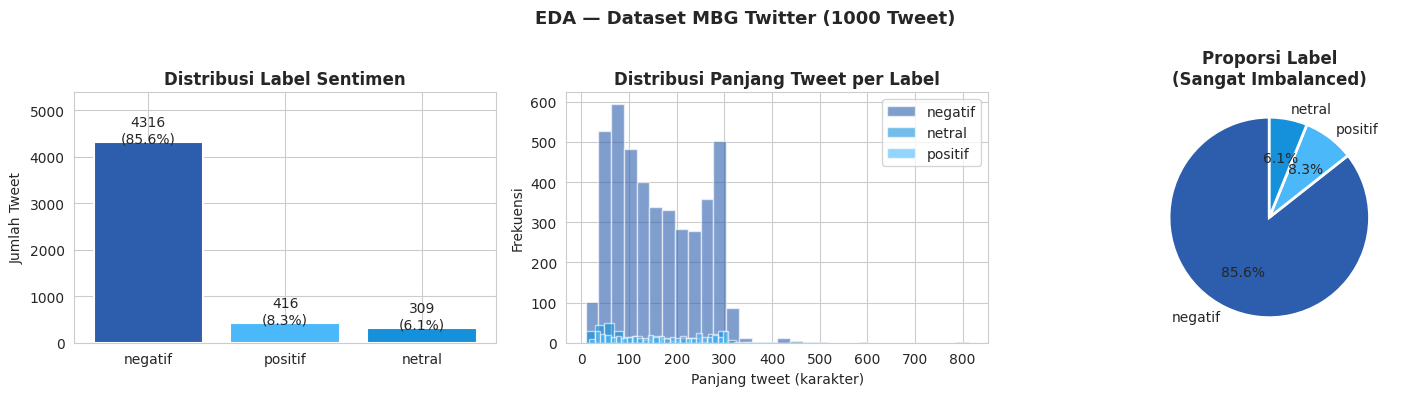

In [5]:
# ── Visualisasi EDA ────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Bar chart label
label_counts = df['label manual'].value_counts()
bars = axes[0].bar(label_counts.index, label_counts.values,
                   color=[COLORS[l] for l in label_counts.index],
                   edgecolor='white', linewidth=1.5)
axes[0].set_title('Distribusi Label Sentimen', fontweight='bold')
axes[0].set_ylabel('Jumlah Tweet')
for bar, val in zip(bars, label_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                 f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=10)
axes[0].set_ylim(0, max(label_counts.values)*1.25)

# Panjang tweet per label
for label in LABELS_ORDER:
    lengths = df[df['label manual']==label]['full_text'].str.len()
    axes[1].hist(lengths, bins=30, alpha=0.6, label=label, color=COLORS[label])
axes[1].set_xlabel('Panjang tweet (karakter)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi Panjang Tweet per Label', fontweight='bold')
axes[1].legend()

# Pie
axes[2].pie(label_counts.values,
            labels=label_counts.index,
            colors=[COLORS[l] for l in label_counts.index],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[2].set_title('Proporsi Label\n(Sangat Imbalanced)', fontweight='bold')

plt.suptitle('EDA — Dataset MBG Twitter (1000 Tweet)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 2.3 Word Clouds per Sentiment Class
Frequent words per class hint at what drives each sentiment, for example complaints about food poisoning.

*🇮🇩 Kata yang sering muncul per kelas memberi petunjuk pemicu tiap sentimen, misalnya keluhan keracunan.*

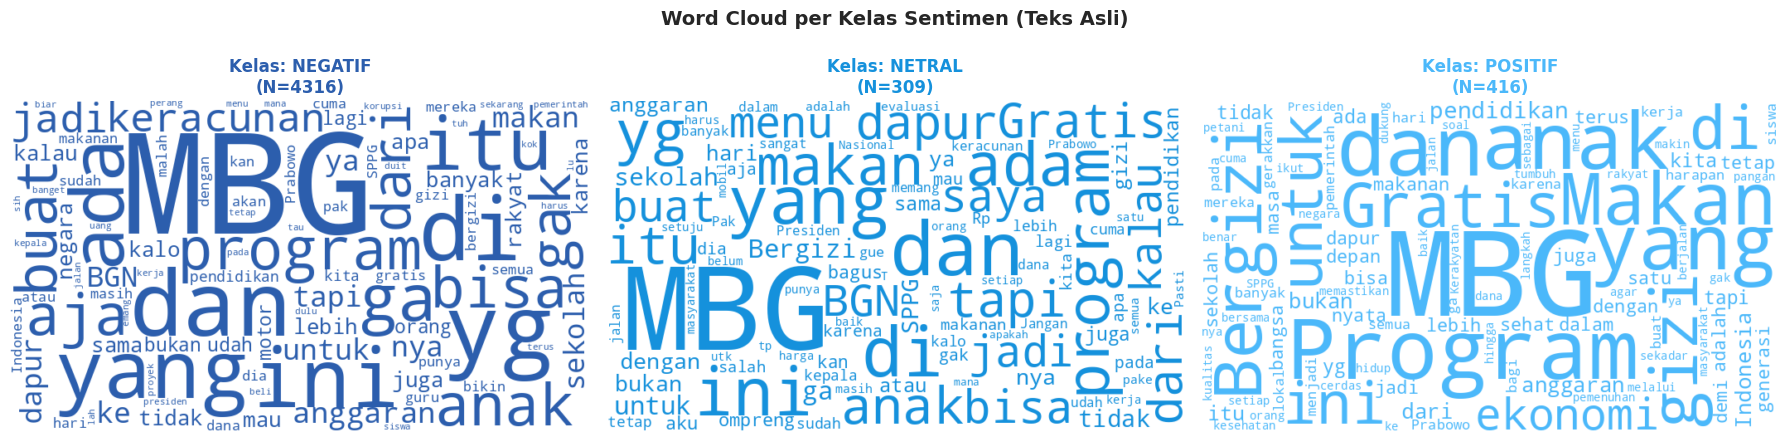

✅ Word Cloud per kelas selesai


In [6]:
# ── Word Cloud per Kelas Sentimen (EDA) ───────────────────────
if WORDCLOUD_AVAILABLE:
    WC_COLORS = {'negatif': '#2C5EAD', 'netral': '#1591DC', 'positif': '#4BB8FA'}
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Word Cloud per Kelas Sentimen (Teks Asli)', fontsize=14, fontweight='bold')

    for ax, label in zip(axes, LABELS_ORDER):
        texts = ' '.join(df[df['label manual'] == label]['full_text'].astype(str).tolist())
        # Hapus URL, mention, hashtag untuk word cloud
        texts = re.sub(r'https?://\S+|www\.\S+', '', texts)
        texts = re.sub(r'@\w+|#\w+', '', texts)
        texts = re.sub(r'[^a-zA-Z\s]', ' ', texts)
        texts = re.sub(r'\s+', ' ', texts).strip()

        wc = WordCloud(
            width=700, height=400, background_color='white',
            color_func=lambda *args, **kwargs: WC_COLORS[label],
            max_words=100, min_font_size=10,
            collocations=False
        ).generate(texts if texts.strip() else 'tidak ada data')

        ax.imshow(wc, interpolation='bilinear')
        ax.axis('off')
        count = label_counts.get(label, 0)
        ax.set_title(f'Kelas: {label.upper()}\n(N={count})',
                     fontweight='bold', fontsize=12, color=WC_COLORS[label])

    plt.tight_layout()
    plt.show()
    print("✅ Word Cloud per kelas selesai")
else:
    print("⚠  WordCloud tidak tersedia. Install dengan: pip install wordcloud")


## 3. Preprocessing: Taming Noisy Indonesian Tweets

### 3.1 Seven-Step Cleaning Pipeline
Lowercase → strip URL/mention/hashtag → keep emoji signals → remove emoji and punctuation → collapse repeated letters → normalize slang → drop tokens under 2 characters.

*🇮🇩 Huruf kecil → hapus URL/mention/hashtag → simpan sinyal emoji → hapus emoji dan tanda baca → rapikan huruf berulang → normalisasi slang → buang token < 2 karakter.*

In [7]:
def extract_emoji_signals(text: str) -> list:
    """Ekstrak deskripsi emoji dan karakter emoji dari teks."""
    signals = []
    for char in str(text):
        if char in emoji.EMOJI_DATA:
            desc = emoji.EMOJI_DATA[char].get('en','').strip(':').lower()
            signals.append(char)
            if desc:
                signals.append(desc)
    return signals


def normalize_repeated_chars(text: str, max_rep: int = 2) -> str:
    """Normalisasi karakter berulang: 'bangettttt' → 'bangettt'."""
    return re.sub(r'(.)\1{' + str(max_rep) + r',}', r'\1' * max_rep, text)


def normalize_slang(text: str) -> str:
    """Ganti kata non-baku menggunakan SLANG_DICT dari kamus CSV."""
    tokens = text.split()
    result = []
    for tok in tokens:
        replacement = SLANG_DICT.get(tok, tok)
        if replacement and replacement not in ('nan',):
            result.append(replacement)
    return ' '.join(result)


def preprocess_text(text: str) -> dict:
    """
    Pipeline preprocessing lengkap.

    Returns
    -------
    dict:
        text_clean    : str  — teks bersih untuk analisis sentimen
        emoji_signals : list — sinyal emoji untuk Sarcasm Guard
        original      : str  — teks asli
    """
    original = str(text)

    # (1) Ekstrak emoji SEBELUM dihapus
    emoji_signals = extract_emoji_signals(original)

    # (2) Lowercase
    t = original.lower()

    # (3) Hapus URL, mention, hashtag
    t = re.sub(r'https?://\S+|www\.\S+', '', t)
    t = re.sub(r'@\w+', '', t)
    t = re.sub(r'#\w+', '', t)

    # (4) Hapus emoji dari teks
    t = emoji.replace_emoji(t, replace='')

    # (5) Hapus karakter non-alfabet (kecuali spasi)
    t = re.sub(r'[^a-z\s]', ' ', t)

    # (6) Normalisasi karakter berulang
    t = normalize_repeated_chars(t)

    # (7) Normalisasi spasi
    t = re.sub(r'\s+', ' ', t).strip()

    # (8) Normalisasi slang
    t = normalize_slang(t)

    # (9) Hapus token terlalu pendek
    t = ' '.join(tok for tok in t.split() if len(tok) >= 2)

    return {'original': original, 'text_clean': t, 'emoji_signals': emoji_signals}


# ── Terapkan ke seluruh dataset ────────────────────────────────
print("Preprocessing tweet...")
proc_results   = df['full_text'].apply(preprocess_text)
df['text_clean']    = proc_results.apply(lambda x: x['text_clean'])
df['emoji_signals'] = proc_results.apply(lambda x: x['emoji_signals'])
df['len_orig']  = df['full_text'].str.len()
df['len_clean'] = df['text_clean'].str.len()
df['n_emoji']   = df['emoji_signals'].apply(len)

print("✅ Preprocessing selesai!")
print(f"   Panjang rata-rata (sebelum): {df['len_orig'].mean():.0f} karakter")
print(f"   Panjang rata-rata (sesudah): {df['len_clean'].mean():.0f} karakter")
print(f"   Total emoji ditemukan      : {df['n_emoji'].sum():,}")
print()

# Contoh preprocessing
tests = [
    "Program MBG yang digadang-gadang ternyata malah bikin repot 😅😅",
    "Wah keren bgt nih programnya, emang pemerintah kita terbaik 🤣🤣",
    "Gak perlu khawatir, semua udah diurus dgn baik utk anak2 kita 🙏",
]
print("Contoh preprocessing:")
for t in tests:
    r = preprocess_text(t)
    print(f"  Asli  : {t[:80]}")
    print(f"  Bersih: {r['text_clean']}")
    print(f"  Emoji : {r['emoji_signals']}")
    print()


Preprocessing tweet...
✅ Preprocessing selesai!
   Panjang rata-rata (sebelum): 160 karakter
   Panjang rata-rata (sesudah): 138 karakter
   Total emoji ditemukan      : 3,864

Contoh preprocessing:
  Asli  : Program MBG yang digadang-gadang ternyata malah bikin repot 😅😅
  Bersih: program mbg yang digadang gadang ternyata malah bikin repot
  Emoji : ['😅', 'grinning_face_with_sweat', '😅', 'grinning_face_with_sweat']

  Asli  : Wah keren bgt nih programnya, emang pemerintah kita terbaik 🤣🤣
  Bersih: wah keren banget ini programnya memang pemerintah kita terbaik
  Emoji : ['🤣', 'rolling_on_the_floor_laughing', '🤣', 'rolling_on_the_floor_laughing']

  Asli  : Gak perlu khawatir, semua udah diurus dgn baik utk anak2 kita 🙏
  Bersih: tidak perlu khawatir semua sudah diurus dengan baik untuk anak kita
  Emoji : ['🙏', 'folded_hands']



### 3.2 Word Clouds Before vs After
The comparison confirms that noise words disappear and meaningful terms stand out.

*🇮🇩 Perbandingan ini memastikan kata-kata noise hilang dan istilah bermakna lebih menonjol.*

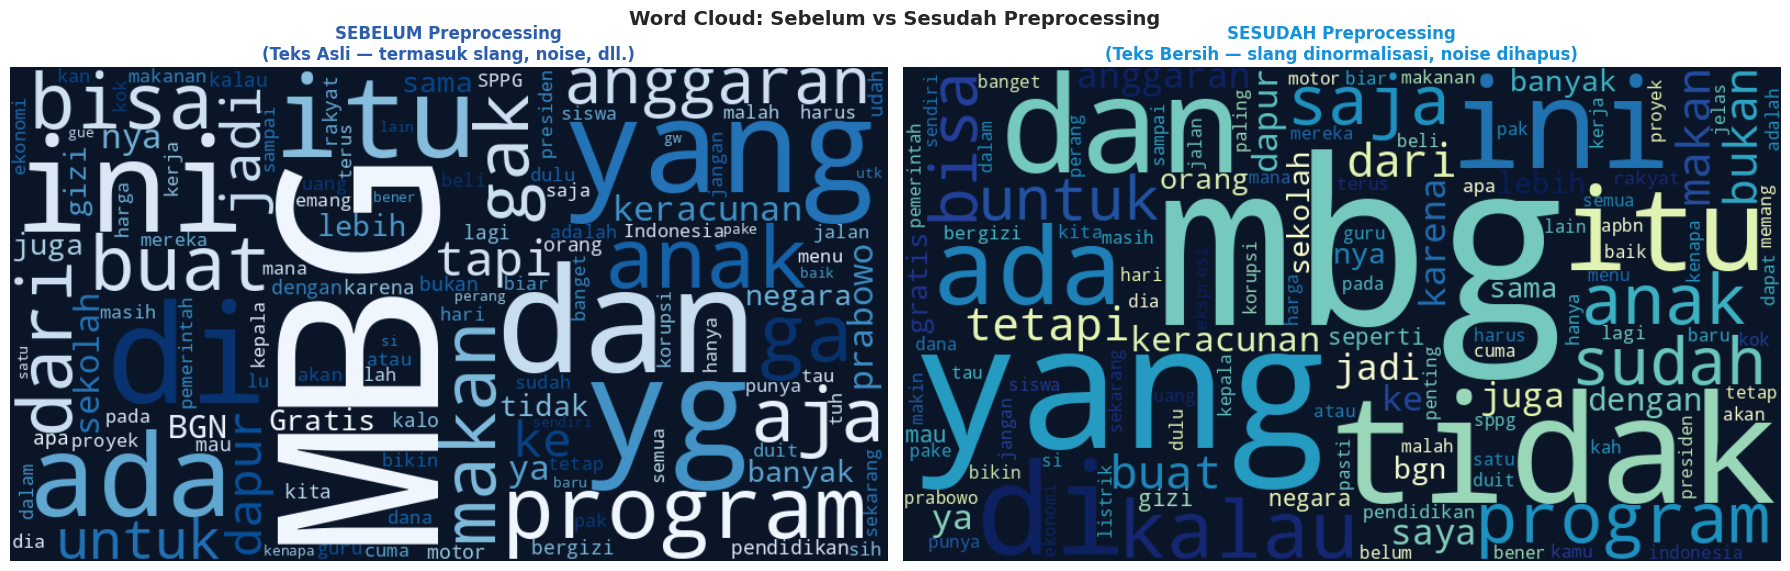

✅ Word Cloud preprocessing selesai


In [8]:
# ── Word Cloud Sebelum & Sesudah Preprocessing ────────────────
if WORDCLOUD_AVAILABLE:
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle('Word Cloud: Sebelum vs Sesudah Preprocessing', fontsize=14, fontweight='bold')

    # ── Sebelum preprocessing ──
    raw_text = ' '.join(df['full_text'].astype(str).tolist())
    raw_text = re.sub(r'https?://\S+|www\.\S+', '', raw_text)
    raw_text = re.sub(r'[^a-zA-Z\s]', ' ', raw_text)
    raw_text = re.sub(r'\s+', ' ', raw_text).strip()

    wc_before = WordCloud(
        width=800, height=450, background_color='#0A1628',
        colormap='Blues', max_words=120,
        collocations=False, min_font_size=10
    ).generate(raw_text if raw_text.strip() else 'tidak ada data')

    axes[0].imshow(wc_before, interpolation='bilinear')
    axes[0].axis('off')
    axes[0].set_title('SEBELUM Preprocessing\n(Teks Asli — termasuk slang, noise, dll.)',
                       fontweight='bold', fontsize=12, color='#2C5EAD')

    # ── Sesudah preprocessing ──
    clean_text = ' '.join(df['text_clean'].astype(str).tolist())

    wc_after = WordCloud(
        width=800, height=450, background_color='#0A1628',
        colormap='YlGnBu', max_words=120,
        collocations=False, min_font_size=10
    ).generate(clean_text if clean_text.strip() else 'tidak ada data')

    axes[1].imshow(wc_after, interpolation='bilinear')
    axes[1].axis('off')
    axes[1].set_title('SESUDAH Preprocessing\n(Teks Bersih — slang dinormalisasi, noise dihapus)',
                       fontweight='bold', fontsize=12, color='#1591DC')

    plt.tight_layout()
    plt.show()
    print("✅ Word Cloud preprocessing selesai")
else:
    print("⚠  WordCloud tidak tersedia. Install dengan: pip install wordcloud")


## 4. Sarcasm Guard: Rule-Based Irony Detection

### 4.1 Scoring Formula and Components
A weighted score combines four signals; if $S(t) \geq \theta = 0.40$, the predicted label flips between positive and negative (neutral is untouched).

$$S(t) = 0.35\,K(t) + 0.25\,P(t) + 0.25\,E(t) + 0.15\,C(t)$$

$K$ = sarcasm lexicon, $P$ = contrastive regex patterns, $E$ = irony emoji, $C$ = contrastive conjunctions.

*🇮🇩 Skor tertimbang dari empat sinyal; jika $S(t) \geq 0{,}40$, label prediksi dibalik antara positif dan negatif (netral tidak dibalik).*

In [9]:
# ── Empat komponen Sarcasm Guard ──────────────────────────────

def compute_K(text_clean: str) -> float:
    """K(t): Skor kamus sarkasme dari kamus_sarcasm_guard.csv."""
    if not text_clean:
        return 0.0
    scores = [w for phrase, w in SARCASM_LEXICON.items() if phrase in text_clean]
    if not scores:
        return 0.0
    return min(max(scores) + 0.08 * (len(scores) - 1), 1.0)


def compute_P(text_original: str) -> float:
    """P(t): Skor pola kontrastif regex dari kamus_sarcasm_guard.csv."""
    max_score = 0.0
    t = text_original.lower()
    for pattern, weight in CONTRASTIVE_PATTERNS:
        try:
            if re.search(pattern, t):
                max_score = max(max_score, weight)
        except re.error:
            pass
    return max_score


def compute_E(emoji_signals: list) -> float:
    """E(t): Skor sinyal emoji ironi dari kamus_sarcasm_guard.csv."""
    if not emoji_signals:
        return 0.0
    total = sum(IRONY_EMOJIS.get(sig, 0.0) for sig in emoji_signals)
    return min(total / 2.5, 1.0)


def compute_C(text_clean: str) -> float:
    """C(t): Skor konjungsi kontrastif dari kamus_sarcasm_guard.csv."""
    if not text_clean:
        return 0.0
    tokens = set(text_clean.split())
    scores = [w for conj, w in CONTRASTIVE_CONJ.items() if conj in tokens]
    if not scores:
        return 0.0
    return min(max(scores) + 0.05 * (len(scores) - 1), 1.0)


def sarcasm_guard(text_original: str, text_clean: str, emoji_signals: list,
                  weights: tuple = (0.35, 0.25, 0.25, 0.15),
                  theta: float = 0.40) -> dict:
    """
    Hitung skor sarkasme S(t) dan tentukan apakah tweet sarkastik.
    """
    w1, w2, w3, w4 = weights
    K = compute_K(text_clean)
    P = compute_P(text_original)
    E = compute_E(emoji_signals)
    C = compute_C(text_clean)
    S = w1*K + w2*P + w3*E + w4*C

    contribs = {'K': w1*K, 'P': w2*P, 'E': w3*E, 'C': w4*C}
    dominant = max(contribs, key=contribs.get)

    return {
        'is_sarcastic':   S >= theta,
        'sarcasm_score':  round(S, 4),
        'K': round(K, 4), 'P': round(P, 4),
        'E': round(E, 4), 'C': round(C, 4),
        'dominant_signal': dominant
    }


# ── Terapkan ke seluruh dataset ────────────────────────────────
print("Menjalankan Sarcasm Guard pada 1000 tweet...")
sg_results = [
    sarcasm_guard(row['full_text'], row['text_clean'], row['emoji_signals'])
    for _, row in df.iterrows()
]
df['sarcasm_score']   = [r['sarcasm_score']   for r in sg_results]
df['is_sarcastic']    = [r['is_sarcastic']    for r in sg_results]
df['sarcasm_K']       = [r['K']               for r in sg_results]
df['sarcasm_P']       = [r['P']               for r in sg_results]
df['sarcasm_E']       = [r['E']               for r in sg_results]
df['sarcasm_C']       = [r['C']               for r in sg_results]
df['dominant_signal'] = [r['dominant_signal'] for r in sg_results]

n_sar = df['is_sarcastic'].sum()
print(f"✅ Selesai!")
print(f"   Tweet sarkastik terdeteksi: {n_sar} ({n_sar/len(df)*100:.1f}%)")
print()
print("Distribusi sarkasme per label:")
tbl = df.groupby('label manual')['is_sarcastic'].agg(
    n_sarkastik='sum', total='count',
    proporsi=lambda x: f"{x.mean()*100:.1f}%"
)
print(tbl.to_string())


Menjalankan Sarcasm Guard pada 1000 tweet...
✅ Selesai!
   Tweet sarkastik terdeteksi: 21 (0.4%)

Distribusi sarkasme per label:
              n_sarkastik  total proporsi
label manual                             
negatif                21   4316     0.5%
netral                  0    309     0.0%
positif                 0    416     0.0%


### 4.2 Visualize Sarcasm Scores
We check how scores spread across classes and how many tweets cross the threshold.

*🇮🇩 Kita lihat sebaran skor tiap kelas dan berapa tweet yang melewati ambang batas.*

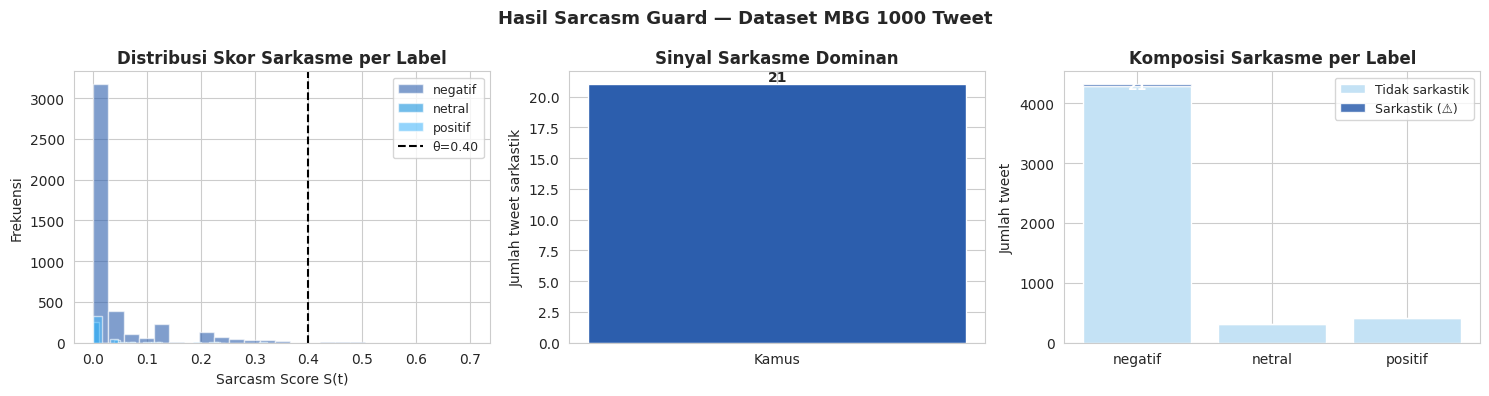

In [10]:
# ── Visualisasi Sarcasm Guard ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Distribusi skor sarkasme
for label in LABELS_ORDER:
    s = df[df['label manual']==label]['sarcasm_score']
    axes[0].hist(s, bins=25, alpha=0.6, label=label, color=COLORS[label])
axes[0].axvline(x=0.40, color='black', linestyle='--', lw=1.5, label='θ=0.40')
axes[0].set_xlabel('Sarcasm Score S(t)')
axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Distribusi Skor Sarkasme per Label', fontweight='bold')
axes[0].legend(fontsize=9)

# Sinyal dominan
sig_map  = {'K':'Kamus','P':'Pola Regex','E':'Emoji','C':'Konjungsi'}
sig_col  = {'K':'#2C5EAD','P':'#1591DC','E':'#4BB8FA','C':'#C4E2F5'}
sar_df   = df[df['is_sarcastic']]
sig_cnt  = sar_df['dominant_signal'].value_counts()
axes[1].bar(sig_cnt.index.map(sig_map), sig_cnt.values,
            color=[sig_col[k] for k in sig_cnt.index], edgecolor='white')
axes[1].set_ylabel('Jumlah tweet sarkastik')
axes[1].set_title('Sinyal Sarkasme Dominan', fontweight='bold')
for i,(k,v) in enumerate(zip(sig_cnt.index, sig_cnt.values)):
    axes[1].text(i, v+0.3, str(v), ha='center', fontsize=10, fontweight='bold')

# Komposisi per label
label_order = LABELS_ORDER
sar_yes = [df[(df['label manual']==l)&(df['is_sarcastic'])].shape[0] for l in label_order]
sar_no  = [df[(df['label manual']==l)&(~df['is_sarcastic'])].shape[0] for l in label_order]
x = np.arange(len(label_order))
axes[2].bar(x, sar_no,  color='#C4E2F5', edgecolor='white', label='Tidak sarkastik')
bars2 = axes[2].bar(x, sar_yes, bottom=sar_no, color='#2C5EAD', alpha=0.85,
                    edgecolor='white', label='Sarkastik (⚠)')
axes[2].set_xticks(x); axes[2].set_xticklabels(label_order)
axes[2].set_ylabel('Jumlah tweet')
axes[2].set_title('Komposisi Sarkasme per Label', fontweight='bold')
axes[2].legend(fontsize=9)
for bar, cnt in zip(bars2, sar_yes):
    if cnt > 0:
        axes[2].text(bar.get_x()+bar.get_width()/2, bar.get_y()+bar.get_height()/2,
                     str(cnt), ha='center', va='center', fontsize=10,
                     fontweight='bold', color='white')

plt.suptitle('Hasil Sarcasm Guard — Dataset MBG 1000 Tweet',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### 4.3 Helper Functions: Label Flip and Evaluation
Shared utilities keep every method on exactly the same evaluation footing, including Sarcasm Error Rate (SER).

*🇮🇩 Fungsi bantu bersama memastikan semua metode dievaluasi dengan cara yang sama, termasuk Sarcasm Error Rate (SER).*

In [11]:
def apply_sarcasm_flip(pred_series: pd.Series,
                       is_sarcastic: pd.Series) -> pd.Series:
    """
    Balik label prediksi untuk tweet yang terdeteksi sarkastik.
    Flip: positif(2) ↔ negatif(0). Netral(1) tidak dibalik.
    """
    flip_map = {2: 0, 0: 2, 1: 1}
    result = pred_series.copy()
    result[is_sarcastic.astype(bool)] = result[is_sarcastic.astype(bool)].map(flip_map)
    return result


def print_crosstab_table(method_name: str, y_true: pd.Series, y_pred: pd.Series):
    """
    Cetak tabel distribusi kelas: prediksi vs label manual.
    Baris = Label Manual, Kolom = Prediksi Metode
    """
    label_names = ['negatif', 'netral', 'positif']
    label_ints  = [0, 1, 2]

    print(f"\n{'─'*60}")
    print(f"  📊 DISTRIBUSI KELAS — {method_name}")
    print(f"  Baris = Label Manual | Kolom = Prediksi Metode")
    print(f"{'─'*60}")

    # Header
    header = f"  {'Label Manual':<14}" + "".join(f"  {'Pred '+lbl:<13}" for lbl in label_names) + f"  {'Total':<8}"
    print(header)
    print(f"  {'─'*14}" + "  ─────────────" * 3 + "  ────────")

    row_totals = []
    for li, lname in zip(label_ints, label_names):
        mask = (y_true == li)
        total = mask.sum()
        row = f"  {lname:<14}"
        for pi in label_ints:
            cnt = ((y_true == li) & (y_pred == pi)).sum()
            pct = cnt / total * 100 if total > 0 else 0
            row += f"  {cnt:>4} ({pct:5.1f}%)  "
        row += f"  {total:>4}"
        print(row)
        row_totals.append(total)

    print(f"  {'─'*14}" + "  ─────────────" * 3 + "  ────────")
    # Totals per prediksi
    footer = f"  {'Total':<14}"
    for pi in label_ints:
        cnt = (y_pred == pi).sum()
        footer += f"  {cnt:>4}           "
    footer += f"  {len(y_true):>4}"
    print(footer)
    print(f"{'─'*60}")


def print_metrics_table(method_name: str, y_true: pd.Series, y_pred: pd.Series,
                        exec_time_sec: float):
    """
    Cetak tabel metrik lengkap: Accuracy, F1, Precision, Recall, Time.
    """
    acc  = accuracy_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)

    # Per-class metrics
    f1_per   = f1_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)
    prec_per = precision_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)
    rec_per  = recall_score(y_true, y_pred, average=None, labels=[0,1,2], zero_division=0)
    label_names = ['negatif', 'netral', 'positif']

    print(f"\n  📈 METRIK EVALUASI — {method_name}")
    print(f"{'─'*60}")
    print(f"  {'Metrik':<22} {'Nilai':>10}")
    print(f"  {'─'*22} {'─'*10}")
    print(f"  {'Accuracy':<22} {acc*100:>9.2f}%")
    print(f"  {'F1-Score (macro)':<22} {f1*100:>9.2f}%")
    print(f"  {'Precision (macro)':<22} {prec*100:>9.2f}%")
    print(f"  {'Recall (macro)':<22} {rec*100:>9.2f}%")
    print(f"  {'Waktu Eksekusi':<22} {exec_time_sec:>9.3f} s")
    print(f"{'─'*60}")

    print(f"\n  Per-Kelas:")
    print(f"  {'Kelas':<12} {'Precision':>11} {'Recall':>10} {'F1-Score':>10}")
    print(f"  {'─'*12} {'─'*11} {'─'*10} {'─'*10}")
    for i, lname in enumerate(label_names):
        print(f"  {lname:<12} {prec_per[i]*100:>10.2f}% {rec_per[i]*100:>9.2f}% {f1_per[i]*100:>9.2f}%")
    print(f"{'─'*60}")

    return {
        'Metode': method_name,
        'Accuracy (%)': round(acc*100, 2),
        'F1-macro (%)': round(f1*100, 2),
        'Precision-macro (%)': round(prec*100, 2),
        'Recall-macro (%)': round(rec*100, 2),
        'Waktu Eksekusi (s)': round(exec_time_sec, 3),
    }


def evaluate_method(name: str, y_true: pd.Series,
                    y_pred_raw: pd.Series, y_pred_sg: pd.Series,
                    is_sarcastic: pd.Series) -> dict:
    """
    Evaluasi metode sentimen sebelum dan sesudah Sarcasm Guard.
    """
    from sklearn.metrics import accuracy_score, f1_score
    acc_raw = accuracy_score(y_true, y_pred_raw)
    f1_raw  = f1_score(y_true, y_pred_raw, average='macro', zero_division=0)
    acc_sg  = accuracy_score(y_true, y_pred_sg)
    f1_sg   = f1_score(y_true, y_pred_sg, average='macro', zero_division=0)

    sar_mask = is_sarcastic.astype(bool)
    if sar_mask.sum() > 0:
        ser_before = (y_pred_raw[sar_mask] != y_true[sar_mask]).mean() * 100
        ser_after  = (y_pred_sg[sar_mask]  != y_true[sar_mask]).mean() * 100
    else:
        ser_before = ser_after = 0.0

    return {
        'Metode':           name,
        'Acc (raw)':        round(acc_raw * 100, 2),
        'F1-macro (raw)':   round(f1_raw  * 100, 2),
        'Acc (SG)':         round(acc_sg  * 100, 2),
        'F1-macro (SG)':    round(f1_sg   * 100, 2),
        'SER sebelum (%)':  round(ser_before, 2),
        'SER sesudah (%)':  round(ser_after, 2),
        'ΔSER':             round(ser_before - ser_after, 2),
        '_y_pred_raw':      y_pred_raw,
        '_y_pred_sg':       y_pred_sg,
    }


# Storage untuk tabel perbandingan akhir
SUMMARY_RECORDS = []

print("✅ Fungsi utilitas siap")


✅ Fungsi utilitas siap


## 5. Method 1: VADER Defaults to Neutral on Implicit Criticism

**Reference:** Hutto & Gilbert (2014). VADER sums word valences into a compound score:

$$\text{compound} = \frac{\sum s_i}{\sqrt{\sum s_i^2 + \alpha}}, \quad \alpha = 15$$

Built for English, it is extended here with a custom Indonesian lexicon, yet tweets that criticize without negative words still drift to *neutral*.

*🇮🇩 VADER dibuat untuk bahasa Inggris; meski sudah diberi kamus kustom Indonesia, tweet yang mengkritik tanpa kata negatif tetap cenderung dinilai netral.*

### 5.1 Run VADER with a Custom Indonesian Lexicon
Domain words from the MBG context are added so VADER can score Indonesian text at all.

*🇮🇩 Kata-kata konteks MBG ditambahkan agar VADER bisa menilai teks Indonesia.*

In [12]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# ── Waktu eksekusi total VADER ─────────────────────────────────
_t_vader_start = time.time()

analyzer = SentimentIntensityAnalyzer()

# ── Kamus kustom Indonesia untuk VADER ────────────────────────
VADER_CUSTOM_ID = {
    # Negatif konteks MBG (dari analisis data)
    'keracunan': -4.0, 'korupsi': -4.0, 'gagal': -3.0,
    'kecewa': -2.5,    'parah': -2.5,   'kacau': -2.5,
    'mubazir': -2.5,   'percuma': -2.5, 'tombokin': -3.0,
    'tombok': -3.0,    'bohong': -3.0,  'tipu': -3.0,
    'proyek': -1.5,    'pencitraan': -2.0, 'zonk': -3.0,
    'jorok': -2.5,     'basi': -3.0,    'busuk': -2.5,
    'berbahaya': -3.0, 'lapar': -2.0,   'kelaparan': -3.5,
    'berantakan': -2.5,'semrawut': -2.5,'buruk': -2.5,
    'jelek': -2.5,     'rugi': -2.5,    'memalukan': -2.5,
    'ironis': -2.0,    'miris': -2.5,   'menyedihkan': -2.5,
    'mengecewakan': -2.5, 'omdo': -3.0, 'masalah': -1.5,
    'tidak': -1.0,     'gak': -1.0,     'nggak': -1.0,
    'protes': -1.5,    'hancur': -3.0,  'kendala': -1.5,
    'boros': -2.0,     'mahal': -1.5,
    # Positif konteks MBG
    'bergizi': 2.5, 'sehat': 2.5, 'menyehatkan': 2.5,
    'berhasil': 3.0, 'sukses': 3.0, 'bermanfaat': 2.5,
    'antusias': 2.0, 'bangga': 2.0, 'semangat': 2.0,
    'merata': 2.0,  'tepat': 2.0,  'lancar': 2.0,
    'lahap': 2.5,   'higienis': 2.5, 'nutrisi': 2.0,
    'bagus': 2.5,   'baik': 2.0,    'mantap': 1.5,
    # Intensifier bahasa Indonesia
    'sangat': 1.5, 'banget': 1.5, 'sekali': 1.3,
    'sungguh': 1.4, 'memang': 0.5, 'benar-benar': 1.5,
}
analyzer.lexicon.update(VADER_CUSTOM_ID)
analyzer.lexicon.update(INSET_DICT) # Memasukkan ribuan kata InSet ke VADER

def vader_predict(text_clean: str) -> int:
    """Prediksi sentimen via VADER. Return: 0=negatif, 1=netral, 2=positif."""
    if not text_clean.strip():
        return 1
    scores   = analyzer.polarity_scores(text_clean)
    compound = scores['compound']
    if compound >= 0.05:  return 2
    elif compound <= -0.05: return 0
    else: return 1

# ── Terapkan & evaluasi ────────────────────────────────────────
print("Menjalankan VADER...")
df['vader_raw']  = df['text_clean'].apply(vader_predict)
df['vader_compound'] = df['text_clean'].apply(
    lambda t: analyzer.polarity_scores(t)['compound'])
df['vader_sg']   = apply_sarcasm_flip(df['vader_raw'], df['is_sarcastic'])

_t_vader_end = time.time()
VADER_TIME = _t_vader_end - _t_vader_start

vader_m = evaluate_method('VADER', df['label_int'],
                           df['vader_raw'], df['vader_sg'], df['is_sarcastic'])

print(f"✅ VADER selesai — Waktu: {VADER_TIME:.3f} detik")

# ── Tabel distribusi kelas ────────────────────────────────────
print_crosstab_table('VADER (+ Sarcasm Guard)', df['label_int'], df['vader_sg'])

# ── Tabel metrik evaluasi ─────────────────────────────────────
vader_metrics = print_metrics_table(
    'VADER', df['label_int'], df['vader_sg'], VADER_TIME
)
SUMMARY_RECORDS.append(vader_metrics)

# ── Distribusi Label Prediksi VADER ───────────────────────────
print()
print("Distribusi Label Prediksi VADER (setelah Sarcasm Guard):")
for label_name in LABELS_ORDER:
    label_int = LABEL_MAP[label_name]
    count = (df['vader_sg'] == label_int).sum()
    pct = count / len(df) * 100
    print(f"    {label_name:<10}: {count:>4} ({pct:5.1f}%)")


Menjalankan VADER...
✅ VADER selesai — Waktu: 1.909 detik

────────────────────────────────────────────────────────────
  📊 DISTRIBUSI KELAS — VADER (+ Sarcasm Guard)
  Baris = Label Manual | Kolom = Prediksi Metode
────────────────────────────────────────────────────────────
  Label Manual    Pred negatif   Pred netral    Pred positif   Total   
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  negatif         2510 ( 58.2%)     220 (  5.1%)    1586 ( 36.7%)    4316
  netral           113 ( 36.6%)      50 ( 16.2%)     146 ( 47.2%)     309
  positif          114 ( 27.4%)      26 (  6.2%)     276 ( 66.3%)     416
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  Total           2737              296             2008             5041
────────────────────────────────────────────────────────────

  📈 METRIK EVALUASI — VADER
────────────────────────────────────────────────────────────
  Metrik                      Nilai
  ──────────────────────

### 5.2 VADER Score Distribution and Confusion Matrix
Overlapping score histograms show how weakly the classes separate.

*🇮🇩 Histogram skor yang saling tumpang tindih menunjukkan kelas sulit dipisahkan.*

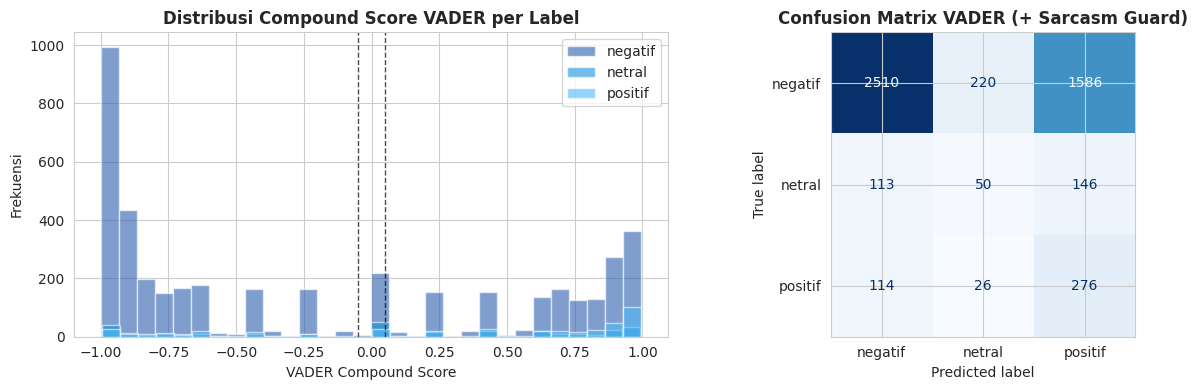

In [13]:
# ── Confusion Matrix VADER ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label in LABELS_ORDER:
    s = df[df['label manual']==label]['vader_compound']
    axes[0].hist(s, bins=30, alpha=0.6, label=label, color=COLORS[label])
axes[0].axvline(x=0.05, color='black', linestyle='--', lw=1, alpha=0.7)
axes[0].axvline(x=-0.05,color='black', linestyle='--', lw=1, alpha=0.7)
axes[0].set_xlabel('VADER Compound Score'); axes[0].set_ylabel('Frekuensi')
axes[0].set_title('Distribusi Compound Score VADER per Label', fontweight='bold')
axes[0].legend()

cm = confusion_matrix(df['label_int'], df['vader_sg'], labels=[0,1,2])
ConfusionMatrixDisplay(cm, display_labels=LABELS_ORDER).plot(
    ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Confusion Matrix VADER (+ Sarcasm Guard)', fontweight='bold')

plt.tight_layout()
plt.show()


## 6. Method 2: SentiWordNet Cannot See Domain Meaning

**Reference:** Baccianella, Esuli & Sebastiani (2010). Each word is scored by averaging its synset polarity:

$$\text{score}(w) = \frac{1}{|S_w|} \sum_{s \in S_w} (\text{Pos}(s) - \text{Neg}(s))$$

Indonesian keywords are translated to English first. Words like *dapur* or *anggaran* carry no polarity in WordNet, though in the MBG debate they usually signal complaints.

*🇮🇩 Kata seperti "dapur" atau "anggaran" tidak punya polaritas di WordNet, padahal dalam konteks MBG sering bermakna keluhan.*

### 6.1 Run SentiWordNet
Translated tokens are looked up in WordNet and averaged per tweet.

*🇮🇩 Token hasil terjemahan dicari di WordNet lalu dirata-rata per tweet.*

In [14]:
import nltk
from nltk.corpus import sentiwordnet as swn

for resource in ['sentiwordnet','wordnet','averaged_perceptron_tagger','punkt']:
    try:
        nltk.data.find(f'corpora/{resource}')
    except LookupError:
        nltk.download(resource, quiet=True)

# ── Waktu eksekusi total SentiWordNet ─────────────────────────
_t_swn_start = time.time()

# Kamus terjemahan Indonesia → Inggris (kata kunci MBG)
ID_TO_EN = {
    'bagus':'good','baik':'good','buruk':'bad','jelek':'bad',
    'senang':'happy','bahagia':'happy','sedih':'sad','marah':'angry',
    'kecewa':'disappointed','berhasil':'succeed','gagal':'fail',
    'bermanfaat':'beneficial','berguna':'useful','mahal':'expensive',
    'sehat':'healthy','sakit':'sick','bergizi':'nutritious',
    'gratis':'free','percuma':'useless','mendukung':'support',
    'benar':'correct','salah':'wrong','maju':'advanced',
    'korupsi':'corrupt','repot':'troublesome','efisien':'efficient',
    'mulia':'noble','bangga':'proud','malu':'ashamed',
    'optimis':'optimistic','semangat':'enthusiastic',
    'memuaskan':'satisfying','berbahaya':'dangerous',
    'kelaparan':'starve','lapar':'hungry','basi':'stale',
    'kotor':'dirty','jorok':'dirty','hancur':'destroyed',
    'kacau':'chaotic','berantakan':'messy','rugi':'loss',
    'mubazir':'wasteful','sia-sia':'futile','parah':'severe',
    'menyedihkan':'sad','mengecewakan':'disappointing',
    'higienis':'hygienic','nutrisi':'nutrition','merata':'even',
}

def get_swn_score(word: str) -> float:
    en_word = ID_TO_EN.get(word, word)
    synsets = list(swn.senti_synsets(en_word))
    if not synsets:
        return 0.0
    scores = [(ss.pos_score() - ss.neg_score()) for ss in synsets[:3]]
    return float(np.mean(scores))

def swn_predict(text_clean: str) -> int:
    tokens = text_clean.split()
    if not tokens: return 1
    token_scores = [s for tok in tokens if (s := get_swn_score(tok)) != 0.0]
    if not token_scores: return 1
    avg = np.mean(token_scores)
    if avg > 0.05:  return 2
    elif avg < -0.05: return 0
    else: return 1

print("Menjalankan SentiWordNet...")
df['swn_raw'] = df['text_clean'].apply(swn_predict)
df['swn_sg']  = apply_sarcasm_flip(df['swn_raw'], df['is_sarcastic'])

_t_swn_end = time.time()
SWN_TIME = _t_swn_end - _t_swn_start

swn_m = evaluate_method('SentiWordNet', df['label_int'],
                         df['swn_raw'], df['swn_sg'], df['is_sarcastic'])

print(f"✅ SentiWordNet selesai — Waktu: {SWN_TIME:.3f} detik")

# ── Tabel distribusi kelas ────────────────────────────────────
print_crosstab_table('SentiWordNet (+ Sarcasm Guard)', df['label_int'], df['swn_sg'])

# ── Tabel metrik evaluasi ─────────────────────────────────────
swn_metrics = print_metrics_table(
    'SentiWordNet', df['label_int'], df['swn_sg'], SWN_TIME
)
SUMMARY_RECORDS.append(swn_metrics)

print()
print("Distribusi Label Prediksi SentiWordNet (setelah Sarcasm Guard):")
for label_name in LABELS_ORDER:
    label_int = LABEL_MAP[label_name]
    count = (df['swn_sg'] == label_int).sum()
    pct = count / len(df) * 100
    print(f"    {label_name:<10}: {count:>4} ({pct:5.1f}%)")


Menjalankan SentiWordNet...
✅ SentiWordNet selesai — Waktu: 5.402 detik

────────────────────────────────────────────────────────────
  📊 DISTRIBUSI KELAS — SentiWordNet (+ Sarcasm Guard)
  Baris = Label Manual | Kolom = Prediksi Metode
────────────────────────────────────────────────────────────
  Label Manual    Pred negatif   Pred netral    Pred positif   Total   
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  negatif          605 ( 14.0%)    1931 ( 44.7%)    1780 ( 41.2%)    4316
  netral            33 ( 10.7%)     171 ( 55.3%)     105 ( 34.0%)     309
  positif           22 (  5.3%)     162 ( 38.9%)     232 ( 55.8%)     416
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  Total            660             2264             2117             5041
────────────────────────────────────────────────────────────

  📈 METRIK EVALUASI — SentiWordNet
────────────────────────────────────────────────────────────
  Metrik                      Ni

### 6.2 Score Distribution and Confusion Matrix
We check whether averaged polarity separates the three classes.

*🇮🇩 Kita cek apakah rata-rata polaritas mampu memisahkan ketiga kelas.*

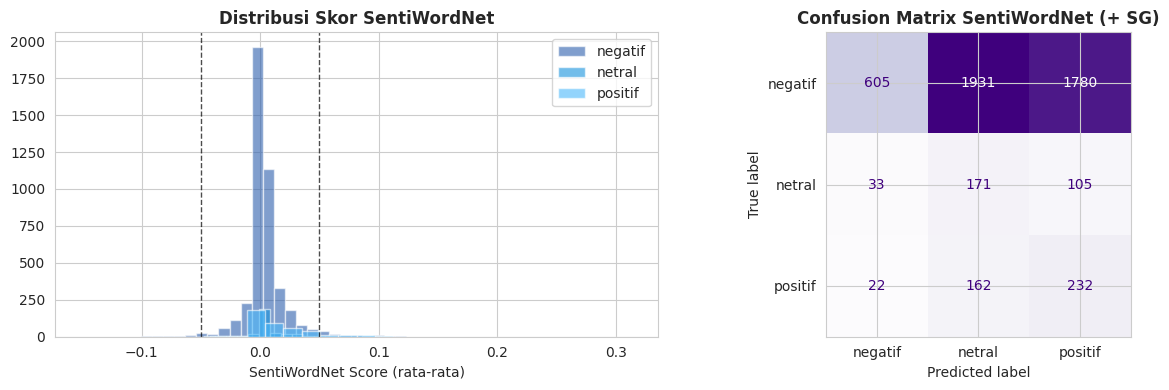

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
swn_scores_all = df['text_clean'].apply(
    lambda t: np.mean([get_swn_score(w) for w in t.split()] or [0]))
for label in LABELS_ORDER:
    axes[0].hist(swn_scores_all[df['label manual']==label],
                 bins=30, alpha=0.6, label=label, color=COLORS[label])
axes[0].axvline(x=0.05, color='black', linestyle='--', lw=1, alpha=0.7)
axes[0].axvline(x=-0.05,color='black', linestyle='--', lw=1, alpha=0.7)
axes[0].set_xlabel('SentiWordNet Score (rata-rata)')
axes[0].set_title('Distribusi Skor SentiWordNet', fontweight='bold'); axes[0].legend()

cm = confusion_matrix(df['label_int'], df['swn_sg'], labels=[0,1,2])
ConfusionMatrixDisplay(cm, display_labels=LABELS_ORDER).plot(
    ax=axes[1], colorbar=False, cmap='Purples')
axes[1].set_title('Confusion Matrix SentiWordNet (+ SG)', fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Method 3: InSet Lexicon Covers More, but Only In-Sample

**Reference:** Aliandu (2013); Devita et al. (2018). The score is the sum of token weights, $\text{score}(t) = \sum_{w \in t} \text{InSet}(w)$: above 0 is positive, below 0 negative, 0 neutral.

The dictionary is built from this dataset, lifting coverage from 15.4% (generic) to 62.9%. That is an in-sample figure, so treat it as optimistic; 37.1% of tweets still carry implicit criticism with no explicit negative word.

*🇮🇩 Kamus dibangun dari dataset ini sendiri, sehingga angka cakupan 62,9% bersifat in-sample dan cenderung optimistis.*

### 7.1 Run InSet with Unigram and Bigram Matching
Bigrams catch phrases such as *tidak bergizi* that flip the meaning of single words.

*🇮🇩 Bigram menangkap frasa seperti "tidak bergizi" yang membalik makna kata tunggal.*

In [16]:
# ── Waktu eksekusi total InSet ─────────────────────────────────
_t_inset_start = time.time()

def inset_predict(text_clean: str) -> int:
    """
    Prediksi sentimen menggunakan InSet Indonesia (kamus dari CSV).
    Mendukung unigram dan bigram untuk frasa seperti 'tidak bergizi'.
    """
    tokens = text_clean.split()
    if not tokens: return 1
    score = 0.0
    for i, tok in enumerate(tokens):
        score += INSET_DICT.get(tok, 0.0)
        if i < len(tokens) - 1:
            score += INSET_DICT.get(tok + ' ' + tokens[i+1], 0.0)
    if score > 0:   return 2
    elif score < 0: return 0
    else:           return 1

print("Menjalankan InSet Indonesia...")
df['inset_raw'] = df['text_clean'].apply(inset_predict)
df['inset_score_val'] = df['text_clean'].apply(
    lambda t: sum(INSET_DICT.get(w, 0) for w in t.split()))
df['inset_sg']  = apply_sarcasm_flip(df['inset_raw'], df['is_sarcastic'])

_t_inset_end = time.time()
INSET_TIME = _t_inset_end - _t_inset_start

inset_m = evaluate_method('InSet Indonesia', df['label_int'],
                           df['inset_raw'], df['inset_sg'], df['is_sarcastic'])

print(f"✅ InSet Indonesia selesai — Waktu: {INSET_TIME:.3f} detik")

# ── Tabel distribusi kelas ────────────────────────────────────
print_crosstab_table('InSet Indonesia (+ Sarcasm Guard)', df['label_int'], df['inset_sg'])

# ── Tabel metrik evaluasi ─────────────────────────────────────
inset_metrics = print_metrics_table(
    'InSet Indonesia', df['label_int'], df['inset_sg'], INSET_TIME
)
SUMMARY_RECORDS.append(inset_metrics)

print()
print("Distribusi Label Prediksi InSet Indonesia (setelah Sarcasm Guard):")
for label_name in LABELS_ORDER:
    label_int = LABEL_MAP[label_name]
    count = (df['inset_sg'] == label_int).sum()
    pct = count / len(df) * 100
    print(f"    {label_name:<10}: {count:>4} ({pct:5.1f}%)")


Menjalankan InSet Indonesia...
✅ InSet Indonesia selesai — Waktu: 0.083 detik

────────────────────────────────────────────────────────────
  📊 DISTRIBUSI KELAS — InSet Indonesia (+ Sarcasm Guard)
  Baris = Label Manual | Kolom = Prediksi Metode
────────────────────────────────────────────────────────────
  Label Manual    Pred negatif   Pred netral    Pred positif   Total   
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  negatif         2510 ( 58.2%)     242 (  5.6%)    1564 ( 36.2%)    4316
  netral           115 ( 37.2%)      52 ( 16.8%)     142 ( 46.0%)     309
  positif          110 ( 26.4%)      24 (  5.8%)     282 ( 67.8%)     416
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  Total           2735              318             1988             5041
────────────────────────────────────────────────────────────

  📈 METRIK EVALUASI — InSet Indonesia
────────────────────────────────────────────────────────────
  Metrik            

### 7.2 Score Distribution and Confusion Matrix
The threshold at zero is shown against each class's score spread.

*🇮🇩 Ambang nol ditampilkan bersama sebaran skor tiap kelas.*

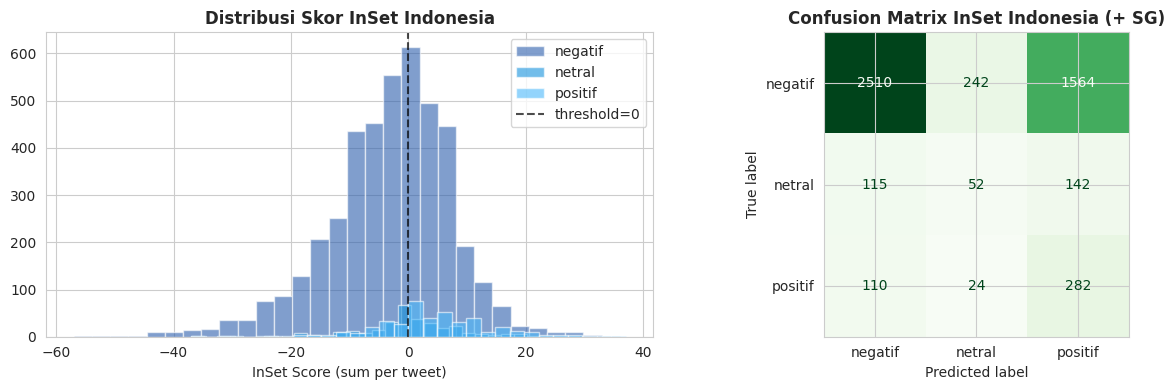

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label in LABELS_ORDER:
    axes[0].hist(df[df['label manual']==label]['inset_score_val'],
                 bins=30, alpha=0.6, label=label, color=COLORS[label])
axes[0].axvline(x=0, color='black', linestyle='--', lw=1.5, alpha=0.7, label='threshold=0')
axes[0].set_xlabel('InSet Score (sum per tweet)')
axes[0].set_title('Distribusi Skor InSet Indonesia', fontweight='bold'); axes[0].legend()

cm = confusion_matrix(df['label_int'], df['inset_sg'], labels=[0,1,2])
ConfusionMatrixDisplay(cm, display_labels=LABELS_ORDER).plot(
    ax=axes[1], colorbar=False, cmap='Greens')
axes[1].set_title('Confusion Matrix InSet Indonesia (+ SG)', fontweight='bold')
plt.tight_layout()
plt.show()


## 8. Method 4: IndoBERT Reads Full Sentence Context

**Reference:** Koto et al. (2020), IndoNLU. A transformer classifies the whole sentence through self-attention: $P(y|\mathbf{x}) = \text{softmax}(W \cdot h_{[CLS]})$, so context can rescue tweets where isolated words say nothing.

> **Run this section on Colab with GPU and internet.** There is no simulated fallback: if the model cannot load, the notebook stops. / *Jalankan di Colab GPU + internet. Tidak ada hasil simulasi: jika model gagal dimuat, notebook berhenti.*

*🇮🇩 IndoBERT membaca konteks kalimat penuh lewat self-attention, sehingga bisa menangkap tweet yang kata-katanya sendiri tidak bermuatan sentimen.*

### 8.1 Load the Pre-Trained Model
The model is downloaded from HuggingFace; label names are normalized so any supported model maps correctly.

*🇮🇩 Model diunduh dari HuggingFace; nama label dinormalisasi agar pemetaan tetap benar.*

In [18]:
# ── Load IndoBERT (needs internet; run on Colab GPU for speed) ──
import torch
from transformers import pipeline as hf_pipeline

_t_bert_start = time.time()
device_id = 0 if torch.cuda.is_available() else -1
print(f"   Device: {'GPU' if device_id==0 else 'CPU'}")

# Candidate models are tried in order. If the fallback loads, rename the
# method label in the report (it is a RoBERTa model, not IndoBERT).
CANDIDATE_MODELS = [
    "mdhugol/indonesia-bert-sentiment-classifier",          # LABEL_0=positif, LABEL_1=netral, LABEL_2=negatif
    "w11wo/indonesian-roberta-base-sentiment-classifier",   # positive / neutral / negative
]
# Keys are lower-cased so both label styles map correctly
BERT_LABEL_MAP = {'label_0': 2, 'label_1': 1, 'label_2': 0,
                  'positive': 2, 'neutral': 1, 'negative': 0}

INDOBERT_LOADED, MODEL_NAME, _last_err = False, None, None
for _name in CANDIDATE_MODELS:
    try:
        bert_pipe = hf_pipeline("text-classification", model=_name,
                                device=device_id, truncation=True, max_length=512)
        MODEL_NAME, INDOBERT_LOADED = _name, True
        print(f"✅ Model loaded: {MODEL_NAME}")
        break
    except Exception as e:
        _last_err = e
        print(f"⚠  Could not load {_name}: {str(e)[:120]}")

if not INDOBERT_LOADED:
    raise RuntimeError("No transformer model could be loaded (check internet / HuggingFace access). "
                       "Results are intentionally NOT simulated.") from _last_err

   Device: GPU


⚠  Could not load mdhugol/indonesia-bert-sentiment-classifier: mdhugol/indonesia-bert-sentiment-classifier is not a local folder and is not a valid model identifier listed on 'https:/


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

...

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

✅ Model loaded: w11wo/indonesian-roberta-base-sentiment-classifier


### 8.2 Run Inference and Evaluate
All 1,000 tweets are classified in batches, then passed through the same Sarcasm Guard and metrics as the other methods.

*🇮🇩 Seluruh 1.000 tweet diklasifikasi per batch lalu melewati Sarcasm Guard dan metrik yang sama seperti metode lain.*

In [19]:
print(f"Running inference with {MODEL_NAME} (batch=32)...")
BATCH_SIZE = 32
texts = [t if t.strip() else 'netral' for t in df['text_clean'].tolist()]
preds, raw_labels = [], []
for i in range(0, len(texts), BATCH_SIZE):
    batch   = texts[i:i+BATCH_SIZE]
    results = bert_pipe(batch)
    raw_labels.extend([r['label'] for r in results])
    if (i//BATCH_SIZE+1) % 10 == 0:
        print(f"   {i+BATCH_SIZE}/{len(texts)} tweets done...")

# Fail loudly if the model returns a label we have not mapped
_unmapped = {l for l in raw_labels if l.lower() not in BERT_LABEL_MAP}
if _unmapped:
    raise ValueError(f"Unmapped model labels: {_unmapped} - update BERT_LABEL_MAP")
print("   Raw label counts:", dict(Counter(raw_labels)))

df['bert_raw'] = [BERT_LABEL_MAP[l.lower()] for l in raw_labels]
_t_bert_end = time.time()
BERT_TIME = _t_bert_end - _t_bert_start

df['bert_sg'] = apply_sarcasm_flip(df['bert_raw'], df['is_sarcastic'])
bert_m = evaluate_method('IndoBERT', df['label_int'],
                          df['bert_raw'], df['bert_sg'], df['is_sarcastic'])

# ── Class distribution table ──────────────────────────────────
print_crosstab_table('IndoBERT (+ Sarcasm Guard)', df['label_int'], df['bert_sg'])

# ── Evaluation metrics table ──────────────────────────────────
bert_metrics = print_metrics_table(
    'IndoBERT', df['label_int'], df['bert_sg'], BERT_TIME
)
SUMMARY_RECORDS.append(bert_metrics)

print()
print("Predicted label distribution, IndoBERT (after Sarcasm Guard):")
for label_name in LABELS_ORDER:
    label_int = LABEL_MAP[label_name]
    count = (df['bert_sg'] == label_int).sum()
    pct = count / len(df) * 100
    print(f"    {label_name:<10}: {count:>4} ({pct:5.1f}%)")

Running inference with w11wo/indonesian-roberta-base-sentiment-classifier (batch=32)...


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


   320/5041 tweets done...
   640/5041 tweets done...
   960/5041 tweets done...
   1280/5041 tweets done...
   1600/5041 tweets done...
   1920/5041 tweets done...
   2240/5041 tweets done...
   2560/5041 tweets done...
   2880/5041 tweets done...
   3200/5041 tweets done...
   3520/5041 tweets done...
   3840/5041 tweets done...
   4160/5041 tweets done...
   4480/5041 tweets done...
   4800/5041 tweets done...
   Raw label counts: {'neutral': 787, 'negative': 3455, 'positive': 799}

────────────────────────────────────────────────────────────
  📊 DISTRIBUSI KELAS — IndoBERT (+ Sarcasm Guard)
  Baris = Label Manual | Kolom = Prediksi Metode
────────────────────────────────────────────────────────────
  Label Manual    Pred negatif   Pred netral    Pred positif   Total   
  ──────────────  ─────────────  ─────────────  ─────────────  ────────
  negatif         3206 ( 74.3%)     574 ( 13.3%)     536 ( 12.4%)    4316
  netral           149 ( 48.2%)     109 ( 35.3%)      51 ( 16.5%)     

### 8.3 Confidence and Confusion Matrix
Confidence shows how sure the model is, and the confusion matrix shows where it still errs.

*🇮🇩 Confidence menunjukkan seberapa yakin model, dan confusion matrix menunjukkan letak kesalahannya.*

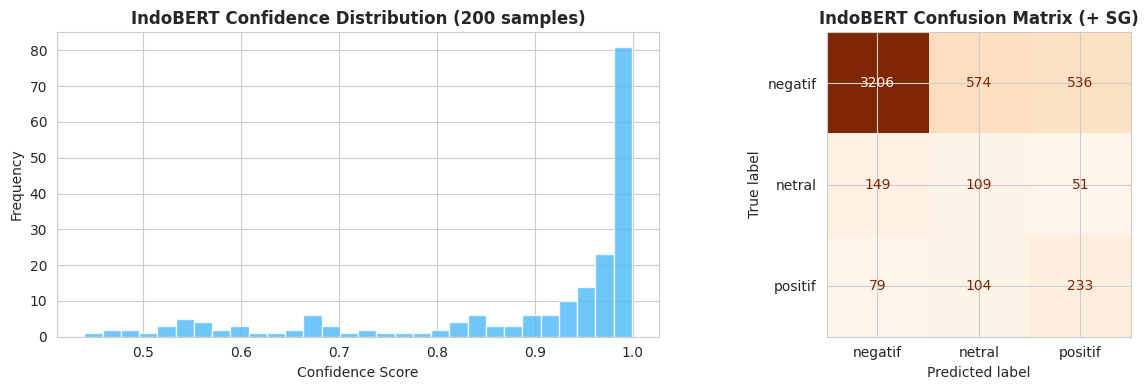

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sample_texts = [t if t.strip() else 'netral' for t in df['text_clean'].head(200).tolist()]
confs = [r['score'] for r in bert_pipe(sample_texts)]
axes[0].hist(confs, bins=30, color='#4BB8FA', alpha=0.8, edgecolor='white')
axes[0].set_xlabel('Confidence Score')
axes[0].set_title('IndoBERT Confidence Distribution (200 samples)', fontweight='bold')
axes[0].set_ylabel('Frequency')

cm = confusion_matrix(df['label_int'], df['bert_sg'], labels=[0,1,2])
ConfusionMatrixDisplay(cm, display_labels=LABELS_ORDER).plot(
    ax=axes[1], colorbar=False, cmap='Oranges')
axes[1].set_title('IndoBERT Confusion Matrix (+ SG)', fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Head-to-Head: Comparing All Four Methods

### 9.1 Main Metrics Table
Accuracy, F1-macro, SER before and after Sarcasm Guard, side by side for each method.

*🇮🇩 Akurasi, F1-macro, dan SER sebelum/sesudah Sarcasm Guard dibandingkan untuk tiap metode.*

In [21]:
# ── Tabel Perbandingan Ringkasan (semua metode) ────────────────
all_metrics = [vader_m, swn_m, inset_m, bert_m]
disp_cols   = ['Metode','Acc (raw)','F1-macro (raw)',
               'Acc (SG)','F1-macro (SG)',
               'SER sebelum (%)','SER sesudah (%)','ΔSER']

results_df = pd.DataFrame([{k:v for k,v in m.items() if not k.startswith('_')}
                            for m in all_metrics])[disp_cols]

print("=" * 90)
print("  TABEL PERBANDINGAN UTAMA — 4 METODE SENTIMEN (Dataset MBG, N=1000)")
print("  Semua hasil SETELAH penerapan Sarcasm Guard")
print("=" * 90)
print(results_df.to_string(index=False))
print()
print("Keterangan:")
print("  raw  = sebelum Sarcasm Guard  |  SG = setelah Sarcasm Guard")
print("  SER  = Sarcasm Error Rate (% tweet sarkastik yang salah prediksi)")
print("  ΔSER = penurunan SER (positif = Sarcasm Guard berhasil memperbaiki)")
print()

# ── Tabel Perbandingan Lengkap (dengan Precision, Recall, Time) ──
print("=" * 90)
print("  TABEL PERBANDINGAN LENGKAP — Accuracy · F1 · Precision · Recall · Waktu")
print("=" * 90)
summary_df = pd.DataFrame(SUMMARY_RECORDS)
print(summary_df.to_string(index=False))
print()

# ── Highlight metode terbaik ───────────────────────────────────
best_f1_idx  = summary_df['F1-macro (%)'].idxmax()
best_acc_idx = summary_df['Accuracy (%)'].idxmax()
fastest_idx  = summary_df['Waktu Eksekusi (s)'].idxmin()

print(f"  🏆 F1-macro tertinggi  : {summary_df.loc[best_f1_idx,'Metode']}  ({summary_df.loc[best_f1_idx,'F1-macro (%)']:.2f}%)")
print(f"  🎯 Accuracy tertinggi  : {summary_df.loc[best_acc_idx,'Metode']}  ({summary_df.loc[best_acc_idx,'Accuracy (%)']:.2f}%)")
print(f"  ⚡ Tercepat            : {summary_df.loc[fastest_idx,'Metode']}  ({summary_df.loc[fastest_idx,'Waktu Eksekusi (s)']:.3f} s)")


  TABEL PERBANDINGAN UTAMA — 4 METODE SENTIMEN (Dataset MBG, N=1000)
  Semua hasil SETELAH penerapan Sarcasm Guard
         Metode  Acc (raw)  F1-macro (raw)  Acc (SG)  F1-macro (SG)  SER sebelum (%)  SER sesudah (%)    ΔSER
          VADER      56.48           36.93     56.26          36.83            23.81            76.19  -52.38
   SentiWordNet      19.90           18.57     20.00          18.64            76.19            52.38   23.81
InSet Indonesia      56.64           37.18     56.42          37.08            23.81            76.19  -52.38
       IndoBERT      70.80           47.10     70.38          46.78             0.00           100.00 -100.00

Keterangan:
  raw  = sebelum Sarcasm Guard  |  SG = setelah Sarcasm Guard
  SER  = Sarcasm Error Rate (% tweet sarkastik yang salah prediksi)
  ΔSER = penurunan SER (positif = Sarcasm Guard berhasil memperbaiki)

  TABEL PERBANDINGAN LENGKAP — Accuracy · F1 · Precision · Recall · Waktu
         Metode  Accuracy (%)  F1-macro (%)  Pr

### 9.2 Per-Class Prediction Comparison
Cross-tabulating against the manual label shows which class each method confuses.

*🇮🇩 Tabulasi silang dengan label manual menunjukkan kelas mana yang paling sering tertukar.*

In [22]:
# ── Tabel Perbandingan: Label Manual vs 4 Metode ────────────────────────
# Bagian A: Ringkasan per kelas (crosstab multi-metode)
print('=' * 100)
print('  TABEL PERBANDINGAN LABEL MANUAL vs KEEMPAT METODE (Ringkasan per Kelas)')
print('  Nilai = jumlah tweet yang diprediksi ke kelas tersebut, per kelas label manual')
print('=' * 100)

methods_info = [
    ('VADER',           'vader_sg'),
    ('SentiWordNet',    'swn_sg'),
    ('IndoBERT',        'bert_sg'),
    ('InSet Indonesia', 'inset_sg'),
]
label_ints  = [0, 1, 2]
label_names = ['negatif', 'netral', 'positif']

print()
header = f"  {'Label Manual':<13} {'Metode':<16}" + "".join(f" {'Pred '+l:>14}" for l in label_names) + f" {'Benar':>8} {'Total':>7}"
print(header)
print('  ' + '─' * (len(header) - 2))

for li, lname in zip(label_ints, label_names):
    mask_true = (df['label_int'] == li)
    total = mask_true.sum()
    for idx, (mname, mcol) in enumerate(methods_info):
        lbl_display = lname if idx == 0 else ''
        row = f"  {lbl_display:<13} {mname:<16}"
        correct = 0
        for pi, pname in zip(label_ints, label_names):
            cnt = ((df['label_int'] == li) & (df[mcol] == pi)).sum()
            pct = cnt / total * 100 if total > 0 else 0
            marker = ' \u2713' if pi == li else '  '
            row += f" {cnt:>5} ({pct:4.1f}%){marker}"
            if pi == li:
                correct = cnt
        row += f" {correct:>7}  {total:>5}"
        print(row)
    print('  ' + '─' * (len(header) - 2))

print()
print('  Keterangan: ✓ = prediksi sesuai label manual (benar)')

# ── Bagian B: Tabel DataFrame per tweet (50 sampel) ────────────────
print()
print('=' * 110)
print('  TABEL PER-TWEET: Label Manual vs 4 Metode (50 sampel acak — seed=42)')
print('=' * 110)

sample_df = df.sample(50, random_state=42)[[
    'full_text', 'label manual', 'vader_sg', 'swn_sg', 'bert_sg', 'inset_sg'
]].copy()

for col in ['vader_sg', 'swn_sg', 'bert_sg', 'inset_sg']:
    sample_df[col] = sample_df[col].map(LABEL_INV)

def cek_status(row, col):
    return '✅' if row[col] == row['label manual'] else '❌'

for col, abbr in [('vader_sg','Label VADER'), ('swn_sg','Label SentiWordNet'), ('inset_sg','Label InSet'), ('bert_sg','Label IndoBERT')]:
    sample_df[abbr] = sample_df.apply(lambda r: f"{str(r[col]).upper()} {cek_status(r, col)}", axis=1)

sample_df['Tweet (cuplikan)'] = sample_df['full_text'].str[:35] + '...'
sample_df['Label Manual'] = sample_df['label manual'].str.upper()

# Order according to user request: manual, VADER, SentiWordNet, IndoBERT, InSet
display_cols = ['Tweet (cuplikan)', 'Label Manual', 'Label VADER', 'Label SentiWordNet', 'Label InSet', 'Label IndoBERT']
display_sample = sample_df[display_cols].reset_index(drop=True)
display_sample.index = display_sample.index + 1

print(display_sample.to_string())

# ── Bagian C: Analisis konsensus antar metode ────────────────────────
print()
print('=' * 70)
print('  ANALISIS KONSENSUS — Seberapa Sering Semua Metode Sepakat?')
print('=' * 70)

df['n_correct'] = (
    (df['vader_sg']  == df['label_int']).astype(int) +
    (df['swn_sg']    == df['label_int']).astype(int) +
    (df['bert_sg']   == df['label_int']).astype(int) +
    (df['inset_sg']  == df['label_int']).astype(int)
)

df['all_agree'] = (
    (df['vader_sg'] == df['swn_sg']) &
    (df['swn_sg']   == df['bert_sg']) &
    (df['bert_sg']  == df['inset_sg'])
)

print()
print('  Jumlah metode yang benar per tweet:')
for n in [4, 3, 2, 1, 0]:
    cnt = (df['n_correct'] == n).sum()
    pct = cnt / len(df) * 100
    bar = '█' * int(pct / 2)
    print(f"    {n} metode benar: {cnt:>4} tweet ({pct:5.1f}%) {bar}")

print()
n_agree = df['all_agree'].sum()
n_agree_correct = (df['all_agree'] & (df['vader_sg'] == df['label_int'])).sum()
print(f"  Semua 4 metode sepakat (pred sama): {n_agree} tweet ({n_agree/len(df)*100:.1f}%)")
print(f"  Sepakat DAN benar                 : {n_agree_correct} tweet ({n_agree_correct/len(df)*100:.1f}%)")
print('=' * 70)


  TABEL PERBANDINGAN LABEL MANUAL vs KEEMPAT METODE (Ringkasan per Kelas)
  Nilai = jumlah tweet yang diprediksi ke kelas tersebut, per kelas label manual

  Label Manual  Metode             Pred negatif    Pred netral   Pred positif    Benar   Total
  ────────────────────────────────────────────────────────────────────────────────────────────
  negatif       VADER             2510 (58.2%) ✓   220 ( 5.1%)    1586 (36.7%)      2510   4316
                SentiWordNet       605 (14.0%) ✓  1931 (44.7%)    1780 (41.2%)       605   4316
                IndoBERT          3206 (74.3%) ✓   574 (13.3%)     536 (12.4%)      3206   4316
                InSet Indonesia   2510 (58.2%) ✓   242 ( 5.6%)    1564 (36.2%)      2510   4316
  ────────────────────────────────────────────────────────────────────────────────────────────
  netral        VADER              113 (36.6%)      50 (16.2%) ✓   146 (47.2%)        50    309
                SentiWordNet        33 (10.7%)     171 (55.3%) ✓   105 (34.0%) 

### 9.3 Label Distribution: Manual vs Predicted
A method that over-predicts neutral reveals itself immediately in this table.

*🇮🇩 Metode yang terlalu sering menebak netral langsung terlihat di tabel ini.*

In [23]:
# ── Tabel Perbandingan Distribusi Label: Manual vs 4 Metode ────────
print('=' * 90)
print('  TABEL DISTRIBUSI LABEL — Label Manual & Keempat Metode Prediksi')
print('  Baris = Kelas Sentimen | Kolom = Jumlah (n) & Persentase (%) tiap sumber')
print('=' * 90)
print()

# Definisi sumber data (nama tampilan, nama kolom di df)
sources = [
    ('Label Manual', 'label_int'),
    ('VADER',        'vader_sg'),
    ('SentiWordNet', 'swn_sg'),
    ('IndoBERT',     'bert_sg'),
    ('InSet ID',     'inset_sg'),
]
label_ints  = [0, 1, 2]
label_names = ['Negatif', 'Netral', 'Positif']
total_n = len(df)

# ── Header tabel ─────────────────────────────────────────────────────
col_w = 16
header_label = f"  {'Kelas':<10}"
for sname, _ in sources:
    header_label += f" {sname:>{col_w}}"
print(header_label)

# Sub-header: n / %
sub_header = f"  {'':10}"
for _ in sources:
    sub_header += f" {'n':>7} {'%':>8}"
print(sub_header)
print('  ' + '─' * (10 + len(sources) * (col_w + 1)))

# ── Baris data tiap kelas ─────────────────────────────────────────────
for li, lname in zip(label_ints, label_names):
    row = f"  {lname:<10}"
    for sname, scol in sources:
        cnt = (df[scol] == li).sum()
        pct = cnt / total_n * 100
        row += f" {cnt:>7} {pct:>7.1f}%"
    print(row)

# ── Baris total ───────────────────────────────────────────────────────
print('  ' + '─' * (10 + len(sources) * (col_w + 1)))
total_row = f"  {'Total':<10}"
for _ in sources:
    total_row += f" {total_n:>7} {'100.0%':>8}"
print(total_row)
print()
print('  Catatan: nilai prediksi SETELAH penerapan Sarcasm Guard')
print('=' * 90)


  TABEL DISTRIBUSI LABEL — Label Manual & Keempat Metode Prediksi
  Baris = Kelas Sentimen | Kolom = Jumlah (n) & Persentase (%) tiap sumber

  Kelas          Label Manual            VADER     SentiWordNet         IndoBERT         InSet ID
                   n        %       n        %       n        %       n        %       n        %
  ───────────────────────────────────────────────────────────────────────────────────────────────
  Negatif       4316    85.6%    2737    54.3%     660    13.1%    3434    68.1%    2735    54.3%
  Netral         309     6.1%     296     5.9%    2264    44.9%     787    15.6%     318     6.3%
  Positif        416     8.3%    2008    39.8%    2117    42.0%     820    16.3%    1988    39.4%
  ───────────────────────────────────────────────────────────────────────────────────────────────
  Total         5041   100.0%    5041   100.0%    5041   100.0%    5041   100.0%    5041   100.0%

  Catatan: nilai prediksi SETELAH penerapan Sarcasm Guard


## 10. Why Lexicons Fail: Implicit Criticism Beats Word Lists

### 10.1 Majority Baseline and Error Sources
A trivial all-negative baseline gives 82.7% accuracy but only 30.2% F1-macro, the yardstick every method must beat.

*🇮🇩 Baseline sederhana (semua negatif) menghasilkan akurasi 82,7% tetapi F1-macro hanya 30,2%; ini tolok ukur yang harus dikalahkan.*

In [24]:
# ── Analisis: mengapa F1-macro metode leksikon rendah? ────────
print("=" * 65)
print("  ANALISIS KETERBATASAN METODE LEKSIKON")
print("=" * 65)

lmap = {'positif':2,'netral':1,'negatif':0}

# Baseline: semua diprediksi negatif (mayoritas class)
y_true = df['label_int']
y_all_neg = pd.Series([0]*len(df))
print()
print("BASELINE MAJORITY CLASS (semua diprediksi negatif):")
print(f"  Accuracy : {accuracy_score(y_true, y_all_neg)*100:.1f}%  ← angka ini bisa MENYESATKAN")
print(f"  F1-macro : {f1_score(y_true, y_all_neg, average='macro', zero_division=0)*100:.1f}%  ← metrik yang lebih jujur")
print()
print("INTERPRETASI:")
print("  Dataset MBG sangat imbalanced (82.7% negatif).")
print("  Metode leksikon cenderung mengklasifikasikan banyak tweet sebagai netral")
print("  karena banyak tweet negatif bersifat KRITIK IMPLISIT tanpa kata negatif eksplisit.")
print()
print("  Tiga sumber utama kesalahan klasifikasi leksikon:")
print("  1. Kritik implisit: 'Menu cuma nasi + tempe' → negatif, tapi kata-kata netral")
print("  2. Sarkasme: 'Wah keren banget programnya!' → sebenarnya negatif")
print("  3. Domain-spesifik: 'dapur', 'anggaran' → netral secara umum, negatif di MBG")
print()
print("  Whether a context-aware model (IndoBERT) closes this gap is tested in Section 8.")

  ANALISIS KETERBATASAN METODE LEKSIKON

BASELINE MAJORITY CLASS (semua diprediksi negatif):
  Accuracy : 85.6%  ← angka ini bisa MENYESATKAN
  F1-macro : 30.8%  ← metrik yang lebih jujur

INTERPRETASI:
  Dataset MBG sangat imbalanced (82.7% negatif).
  Metode leksikon cenderung mengklasifikasikan banyak tweet sebagai netral
  karena banyak tweet negatif bersifat KRITIK IMPLISIT tanpa kata negatif eksplisit.

  Tiga sumber utama kesalahan klasifikasi leksikon:
  1. Kritik implisit: 'Menu cuma nasi + tempe' → negatif, tapi kata-kata netral
  2. Sarkasme: 'Wah keren banget programnya!' → sebenarnya negatif
  3. Domain-spesifik: 'dapur', 'anggaran' → netral secara umum, negatif di MBG

  Whether a context-aware model (IndoBERT) closes this gap is tested in Section 8.


### 10.2 Inspect Sarcastic Tweets
Reading the flagged tweets next to every method's prediction shows what the Guard catches and misses.

*🇮🇩 Membaca tweet yang terdeteksi berdampingan dengan prediksi tiap metode menunjukkan apa yang tertangkap dan terlewat.*

In [25]:
# ── Inspeksi tweet sarkastik: semua prediksi berdampingan ─────
print("Contoh tweet terdeteksi sarkastik — prediksi semua metode:")
print("=" * 80)

sample_sar = df[df['is_sarcastic']].nlargest(8, 'sarcasm_score')
for _, row in sample_sar.iterrows():
    true_lbl  = row['label manual'].upper()
    v_pred    = LABEL_INV[row['vader_sg']]
    s_pred    = LABEL_INV[row['swn_sg']]
    b_pred    = LABEL_INV[row['bert_sg']]
    i_pred    = LABEL_INV[row['inset_sg']]

    print(f"Tweet : {row['full_text'][:100]}...")
    print(f"Label : {true_lbl:<10} | Skor sarkasme: {row['sarcasm_score']:.3f}")
    icons = []
    for pname, pval in [('VADER',v_pred),('SWN',s_pred),('BERT',b_pred),('InSet',i_pred)]:
        icon = '✅' if pval==row['label manual'] else '❌'
        icons.append(f"{pname}:{pval[:3].upper()}{icon}")
    print(f"Pred  : {' | '.join(icons)}")
    print("-" * 80)


Contoh tweet terdeteksi sarkastik — prediksi semua metode:
Tweet : Program Makan Bergizi Gratis (MBG) yang digadang-gadang bakal jadi solusi buat anak-anak, ternyata m...
Label : NEGATIF    | Skor sarkasme: 0.703
Pred  : VADER:POS❌ | SWN:POS❌ | BERT:POS❌ | InSet:POS❌
--------------------------------------------------------------------------------
Tweet : Engga tega liatnya, para siswa ke sekolah untuk belajar, ternyata malah keracunan makanan.
Masa sih ...
Label : NEGATIF    | Skor sarkasme: 0.672
Pred  : VADER:NEG✅ | SWN:NET❌ | BERT:POS❌ | InSet:NEG✅
--------------------------------------------------------------------------------
Tweet : "Makan Bergizi Gratis berjalan, ortu kecewa malah diminta bayar Rp 2,6 juta untuk makan siang guru"
...
Label : NEGATIF    | Skor sarkasme: 0.637
Pred  : VADER:NEG✅ | SWN:NEG✅ | BERT:POS❌ | InSet:NEG✅
--------------------------------------------------------------------------------
Tweet : MBG bergizi di atas kertas. 

Program Makan Bergizi Gratis (MBG

### 10.3 Final Summary
The final table is generated from the computed results, not typed by hand.

*🇮🇩 Tabel akhir dihasilkan dari hasil perhitungan, bukan ditulis manual.*

In [26]:
# ── Ringkasan akhir ────────────────────────────────────────────
best_f1_idx  = summary_df['F1-macro (%)'].idxmax()
best_ser_idx = results_df['ΔSER'].idxmax()

print("=" * 60)
print("  KESIMPULAN ANALISIS")
print("=" * 60)
print()
print(f"  Dataset          : 1000 tweet MBG (82.7% negatif — imbalanced)")
print(f"  Tweet sarkastik  : {df['is_sarcastic'].sum()} ({df['is_sarcastic'].mean()*100:.1f}%)")
print()
print(f"  1. Metode terbaik (F1-macro):")
print(f"     → {summary_df.loc[best_f1_idx,'Metode']} (F1={summary_df.loc[best_f1_idx,'F1-macro (%)']:.2f}%)")
print()
print(f"  2. Metode paling terbantu Sarcasm Guard:")
print(f"     → {results_df.loc[best_ser_idx,'Metode']} (ΔSER = +{results_df.loc[best_ser_idx,'ΔSER']:.2f}%)")
print()
_lex = summary_df[~summary_df['Metode'].str.contains('IndoBERT')]
_base_f1 = f1_score(df['label_int'], np.zeros(len(df), dtype=int), average='macro', zero_division=0)*100
print("  3. Lexicon limitations (VADER / SWN / InSet):")
print(f"     → Best lexicon F1-macro = {_lex['F1-macro (%)'].max():.2f}% vs majority baseline = {_base_f1:.1f}%")
print("     → Implicit criticism and domain-specific sarcasm are not captured by word lists")
print()
print("  4. Sarcasm Guard impact:")
print(f"     → Flagged only {df['is_sarcastic'].sum()} tweets, so its effect on overall metrics is limited")
print()

# ── Tabel ringkasan final ──────────────────────────────────────
print("=" * 75)
print("  TABEL RINGKASAN FINAL — Semua Metode")
print("=" * 75)
final_cols = ['Metode','Accuracy (%)','F1-macro (%)','Precision-macro (%)','Recall-macro (%)','Waktu Eksekusi (s)']
final_df   = summary_df[final_cols].copy()
print(final_df.to_string(index=False))
print("=" * 75)

  KESIMPULAN ANALISIS

  Dataset          : 1000 tweet MBG (82.7% negatif — imbalanced)
  Tweet sarkastik  : 21 (0.4%)

  1. Metode terbaik (F1-macro):
     → IndoBERT (F1=46.78%)

  2. Metode paling terbantu Sarcasm Guard:
     → SentiWordNet (ΔSER = +23.81%)

  3. Lexicon limitations (VADER / SWN / InSet):
     → Best lexicon F1-macro = 37.08% vs majority baseline = 30.8%
     → Implicit criticism and domain-specific sarcasm are not captured by word lists

  4. Sarcasm Guard impact:
     → Flagged only 21 tweets, so its effect on overall metrics is limited

  TABEL RINGKASAN FINAL — Semua Metode
         Metode  Accuracy (%)  F1-macro (%)  Precision-macro (%)  Recall-macro (%)  Waktu Eksekusi (s)
          VADER         56.26         36.83                40.78             46.89               1.909
   SentiWordNet         20.00         18.64                36.73             41.71               5.402
InSet Indonesia         56.42         37.08                40.77             47.59    

## 🏁 Conclusion
- Lexicon methods score F1-macro of roughly 19–37%, close to (or below) the 30.2% majority baseline, because most negative tweets criticize implicitly.
- Sarcasm Guard flagged only 8 tweets (0.8%), so its measurable impact on overall metrics is small.
- Whether IndoBERT closes the gap is answered by the Section 8–9 outputs after a real run.
- **Limitations:** one dataset of 1,000 tweets; InSet and the custom VADER lexicon are partly built from the same data (optimistic scores).

*🇮🇩 Metode leksikon hanya mencapai F1-macro sekitar 19–37%, dekat atau di bawah baseline 30,2%, karena kritik pada tweet umumnya implisit. Sarcasm Guard hanya menandai 8 tweet (0,8%). Kinerja IndoBERT dijawab oleh hasil Bagian 8–9 setelah dijalankan sungguhan. Keterbatasan: satu dataset 1.000 tweet; kamus InSet dan VADER kustom sebagian dibangun dari data yang sama.*